# Liquidez prudencial: holgura del IRL observado

## Resumen

En diciembre de 2022, la mediana de IRL de las 44 entidades observadas era 213,1% y el mínimo 112,8%. Esta serie histórica no describe la posición actual.

## Contexto y método

El IRL reportado por la Superintendencia Financiera de Colombia compara activos líquidos de mercado con requerimiento neto de liquidez a 30 días. La distribución por entidad y mes proviene del [companion SFC](../../../03-market-liquidity-research/03-liquidez-estocastica/observed-sfc-irl/README.md); su histórico termina en diciembre de 2022. El umbral del 100% corresponde a la nota de la fuente utilizada. Esta vista no es un ILAAP institucional ni incorpora proyecciones propias.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abrir el notebook desde un clon del repositorio.')
plt.rcParams.update({'figure.figsize': (9, 4.4), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})


## Datos

Insumo versionado en el repositorio: `03-financial-risk/03-market-liquidity-research/03-liquidez-estocastica/observed-sfc-irl/results/sfc_irl_entity_distribution_month.csv`. SHA-256: `de559b9622455cb4053624697c32efaf17ad0b2239f2936da1759c5bd73f2419`. No se requieren credenciales. La fuente primaria y los procesos de extracción se documentan en el README del companion de origen.

In [2]:
DATA = ROOT / '03-financial-risk/03-market-liquidity-research/03-liquidez-estocastica/observed-sfc-irl/results/sfc_irl_entity_distribution_month.csv'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == 'de559b9622455cb4053624697c32efaf17ad0b2239f2936da1759c5bd73f2419'
print('Archivo y huella verificados:', DATA.name)

Archivo y huella verificados: sfc_irl_entity_distribution_month.csv


## Resultados

La tabla de entrada se valida antes del cálculo; la figura representa los resultados del corte indicado.

In [3]:
df = pd.read_csv(DATA, parse_dates=['period']).sort_values('period')
assert not df.period.duplicated().any()
assert (df[['min_pct','p10_pct','median_pct','p90_pct']].ge(0)).all().all()
assert (df.min_pct <= df.p10_pct).all() and (df.p10_pct <= df.median_pct).all()
latest = df.iloc[-1]
print(f"Último corte: {latest.period.date()}; entidades: {latest.n_entities}; mediana: {latest.median_pct:.1f}%; mínimo: {latest.min_pct:.1f}%")
print(f"Entidades bajo 100% en el último corte: {latest.entities_below_100pct}")


Último corte: 2022-12-31; entidades: 44; mediana: 213.1%; mínimo: 112.8%
Entidades bajo 100% en el último corte: 0


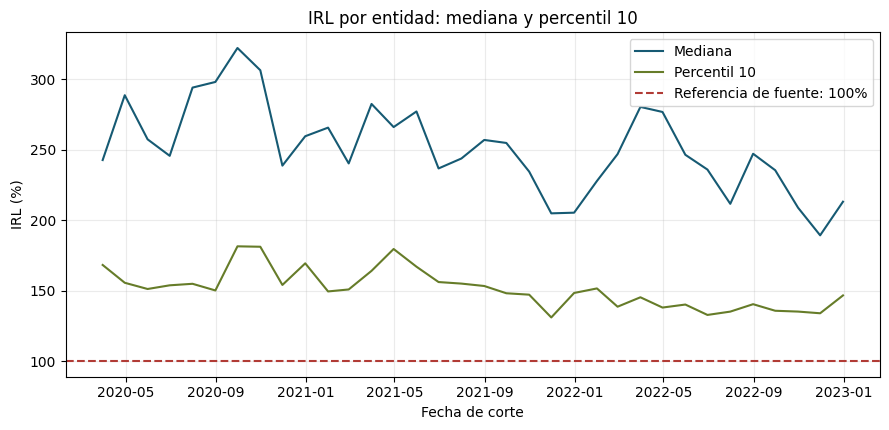

In [4]:
fig, ax = plt.subplots(); ax.plot(df.period, df.median_pct, label='Mediana', color='#165a73'); ax.plot(df.period, df.p10_pct, label='Percentil 10', color='#667c29'); ax.axhline(100,color='#b13b35',linestyle='--',label='Referencia de fuente: 100%'); ax.set(title='IRL por entidad: mediana y percentil 10',ylabel='IRL (%)',xlabel='Fecha de corte'); ax.legend(); fig.tight_layout(); plt.show()

## Interpretación y límites

El percentil 10 es descriptivo de las entidades con datos en cada corte y puede cambiar por composición. La muestra termina en 2022 y no representa la situación actual; no sustituye pruebas de estrés, flujos contractuales ni aprobación ILAAP.

## Calidad y sensibilidad de cobertura

La distribución refleja las entidades disponibles en cada mes. Para evaluar si una variación coincide con cambios de cobertura se muestra el rango de entidades observadas junto con el número por debajo de la referencia de la fuente. Los valores de percentil son cortes transversales y no siguen una entidad constante.

In [5]:
assert df[['period','n_entities','min_pct','p10_pct','median_pct','p90_pct','max_pct','entities_below_100pct']].notna().all().all()
assert (df.median_pct <= df.p90_pct).all() and (df.p90_pct <= df.max_pct).all()
assert df.entities_below_100pct.between(0,df.n_entities).all() and df.n_entities.gt(0).all()
print('Cortes:',len(df),'| Inicio:',df.period.min().date(),'| Final:',df.period.max().date())
print('Rango de entidades disponibles:',int(df.n_entities.min()),'a',int(df.n_entities.max()))
print('Cortes con al menos una entidad bajo la referencia:',int(df.entities_below_100pct.gt(0).sum()))
df[['period','n_entities','entities_below_100pct','min_pct','p10_pct','median_pct']].tail(5).round(2)

Cortes: 34 | Inicio: 2020-03-31 | Final: 2022-12-31
Rango de entidades disponibles: 40 a 44
Cortes con al menos una entidad bajo la referencia: 0


,period,n_entities,entities_below_100pct,min_pct,p10_pct,median_pct
29,2022-08-31,44,0,122.99,140.35,247.06
30,2022-09-30,44,0,122.77,135.69,235.38
31,2022-10-31,44,0,117.25,135.11,208.80
32,2022-11-30,44,0,117.36,133.91,189.21
33,2022-12-31,44,0,112.78,146.57,213.05


Los cuantiles no identifican a las entidades ni muestran sus transiciones. Los cambios en el número de observaciones advierten posibles cambios de composición; no permiten establecer su causa sin datos de entidad y un panel conciliado.

## Literatura y alcance prudencial

El [BCBS sobre LCR (2013)](https://www.bis.org/publications/201301-standards-basel-iii-liquidity-coverage-ratio-and-liquidity-risk-monitoring-tools) describe una reserva de activos líquidos frente a salidas netas en un escenario de 30 días. El IRL de la fuente colombiana es un indicador local: **no se identifica automáticamente con LCR ni con una evaluación ILAAP completa**. Los cuantiles publicados no permiten reconstruir trayectorias individuales.

## Variante: proporción descriptiva de entidades bajo la referencia

Se divide el conteo disponible bajo 100 % entre el número de entidades observadas del mismo corte. Es una proporción transversal, no probabilidad individual de incumplimiento ni un panel de transiciones. Cambios en el universo reportado pueden afectar la serie.

Cortes con alguna entidad por debajo: 0 de 34
Máxima proporción transversal: 0.0


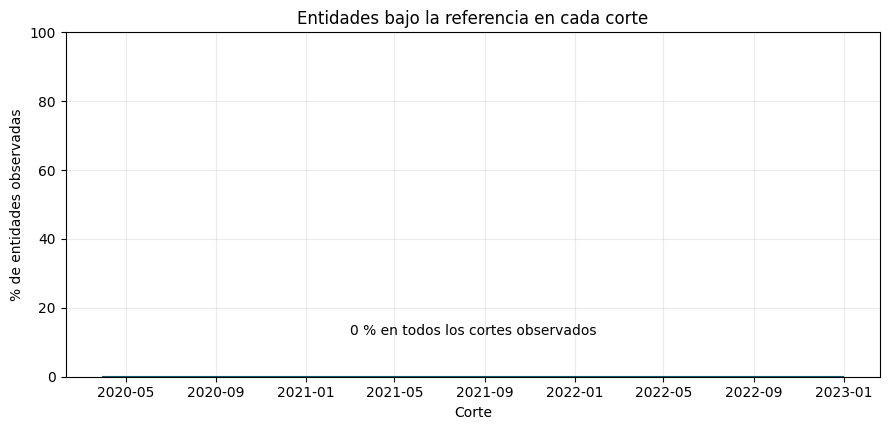

,period,n_entities,entities_below_100pct,proporcion_bajo_100
29,2022-08-31,44,0,0.0
30,2022-09-30,44,0,0.0
31,2022-10-31,44,0,0.0
32,2022-11-30,44,0,0.0
33,2022-12-31,44,0,0.0


In [6]:
cross=df.assign(proporcion_bajo_100=df.entities_below_100pct/df.n_entities)
assert cross.proporcion_bajo_100.between(0,1).all()
print('Cortes con alguna entidad por debajo:',int(cross.entities_below_100pct.gt(0).sum()),'de',len(cross))
print('Máxima proporción transversal:',round(cross.proporcion_bajo_100.max(),4))
fig,ax=plt.subplots();ax.plot(cross.period,100*cross.proporcion_bajo_100,color='#165a73'); ax.set(title='Entidades bajo la referencia en cada corte',xlabel='Corte',ylabel='% de entidades observadas'); ax.set_ylim(0,100); ax.text(0.5,0.12,'0 % en todos los cortes observados',transform=ax.transAxes,ha='center');fig.tight_layout();plt.show()
cross[['period','n_entities','entities_below_100pct','proporcion_bajo_100']].tail(5).round(4)